# T0704 — Kiểm chứng hành vi mắt và ngáp
Dữ liệu synthetic, không phải ground truth hay đánh giá độ chính xác D3S. Ngưỡng đọc từ YAML thật.
Frame invalid luôn trả UNKNOWN. HOLD giữ buffers, tắt cờ sự kiện và loại khoảng không quan sát khỏi timer. Cửa sổ ngáp dùng timestamp video gốc. Timeout reset toàn bộ lịch sử.
Nếu decoder bỏ frame mà caller không gửi UNKNOWN, coordinator không thể nhận biết gap đó.

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
if not (root / 'src').is_dir():
    root = root.parent
assert (root / 'src').is_dir(), 'Run from repository or notebooks directory'
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.temporal.temporal_analyzer import TemporalAnalyzer
from src.utils.contracts import EyeMeasurement, MouthMeasurement
analyzer = TemporalAnalyzer()
settings = analyzer.settings
settings


TemporalSettings(ear_threshold=0.25, closure_time_threshold=1.5, mar_threshold=0.6, yawn_duration_threshold=2.0, yawn_frequency_window=60.0, missing_face_tolerance_frames=5, missing_face_timeout_sec=1.5)

In [2]:
step = 0.1
span = max(settings.closure_time_threshold, settings.yawn_duration_threshold) + 2
records = []
try:
    for t in np.arange(0, 3 * span, step):
        active = span <= t < 2 * span
        missing = span + 0.5 <= t < span + 0.7
        ear = settings.ear_threshold / 2 if active else settings.ear_threshold + 0.1
        mar = settings.mar_threshold + 0.1 if active else 0.0
        eye = EyeMeasurement(left_ear=ear, right_ear=ear, avg_ear=ear, eye_state='CLOSED' if active else 'OPEN')
        mouth = MouthMeasurement(mar=mar, mouth_state='MOUTH_OPEN' if active else 'MOUTH_CLOSED')
        result = analyzer.update(not missing, float(t), eye, mouth)
        row = result.behavior.model_dump()
        row.update(timestamp=float(t), valid=result.is_valid, action=result.action)
        records.append(row)
finally:
    analyzer.reset()
df = pd.DataFrame(records)
assert not df.loc[~df.valid, 'is_yawning_event'].any()
assert not df.loc[~df.valid, 'is_prolonged_closure'].any()
df.groupby('action').size()


action
CONTINUE    118
HOLD          2
dtype: int64

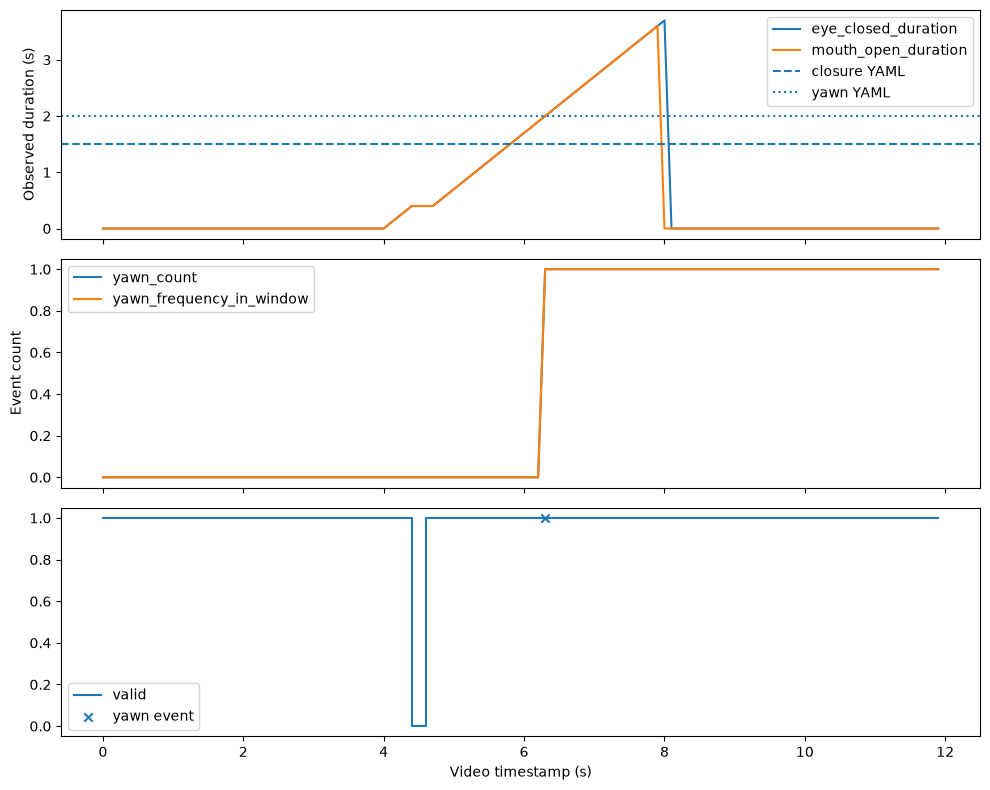

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
df.plot(x='timestamp', y=['eye_closed_duration', 'mouth_open_duration'], ax=axes[0])
axes[0].axhline(settings.closure_time_threshold, linestyle='--', label='closure YAML')
axes[0].axhline(settings.yawn_duration_threshold, linestyle=':', label='yawn YAML')
axes[0].set_ylabel('Observed duration (s)')
axes[0].legend()
df.plot(x='timestamp', y=['yawn_count', 'yawn_frequency_in_window'], ax=axes[1])
axes[1].set_ylabel('Event count')
axes[2].step(df.timestamp, df.valid.astype(int), label='valid')
axes[2].scatter(df.loc[df.is_yawning_event, 'timestamp'], np.ones(df.is_yawning_event.sum()), marker='x', label='yawn event')
axes[2].set_xlabel('Video timestamp (s)')
axes[2].legend()
fig.tight_layout()
plt.show()
